<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta7_g%C3%B6rev7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


Harmonik matris boyutu: (128, 128) | Veri tipi: complex128


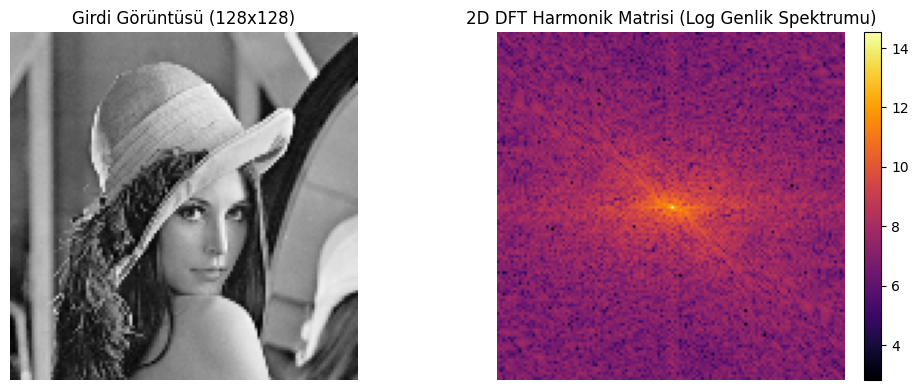

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

def dft_1d_matrix(N):
    """N boyutlu 1D DFT dönüşüm matrisini üretir."""
    n = np.arange(N, dtype=np.float64).reshape((N, 1))
    k = np.arange(N, dtype=np.float64).reshape((1, N))
    return np.exp(-1j * 2.0 * np.pi * (n @ k) / N)

def dft_2d(image):
    """
    Bir resmi (gri tonlu veya renkli) girdi olarak alır ve
    2-boyutlu harmonik matrisini döndürür.
    """
    img = np.asarray(image, dtype=np.float64)

    if img.ndim == 3:
        img = 0.114 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.299 * img[:, :, 2]
    elif img.ndim != 2:
        raise ValueError("Girdi 2D gri tonlu veya 3D renkli bir görüntü olmalıdır.")

    M, N = img.shape
    W_M = dft_1d_matrix(M)
    W_N = dft_1d_matrix(N)

    harmonic_matrix = W_M @ img @ W_N
    return harmonic_matrix

url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img_color = cv2.imdecode(arr, cv2.IMREAD_COLOR)

img_small = cv2.resize(img_color, (128, 128))
img_gray = cv2.cvtColor(img_small, cv2.COLOR_BGR2GRAY)

harmonic_mat = dft_2d(img_gray)
print("Harmonik matris boyutu:", harmonic_mat.shape, "| Veri tipi:", harmonic_mat.dtype)

shifted_spectrum = np.fft.fftshift(harmonic_mat)
log_magnitude = np.log1p(np.abs(shifted_spectrum))

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('Girdi Görüntüsü (128x128)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(log_magnitude, cmap='inferno')
plt.title('2D DFT Harmonik Matrisi (Log Genlik Spektrumu)')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

plt.tight_layout()
plt.show()